# Hamiltonian JEPA (LeHami) — figures and tables of the paper

This notebook regenerates every data figure and every table in the submission
from the folder **`data/`**, and nothing else: no
checkpoint, dataset or cluster result is read. Run it top to bottom.

| folder | contents |
|---|---|
| `data/datasets/` | split manifests and the dataset frames shown in the figures |
| `data/conservative_pendulum/` | probe / rollout metrics, integrator and Jacobian tests, latents, training compute |
| `data/actuated_pendulum/` | probe metrics and features, planning episodes and their FLOP counts, learned $H$ on a grid |

`data/` is produced by `lehami/experiments/src/export_paper_data.py`, which is the only step that
needs the checkpoints and the `.h5` datasets.

**Outputs.** Figures go to `figures/<environment>/<name>.png`; a figure placed in the
appendix carries the suffix `_appendix`. Each table is printed as the LaTeX body the
paper uses, with the paper's value alongside wherever a number is quoted in the text.

**Not regenerated here.** The two method diagrams, `concept_hjepa_properties_actuated.pdf`
(introduction) and `lehami_diagram_f.pdf` (method), are drawn by hand and contain no data.

**Naming.** The method is called **LeHami** in the paper. Run directories keep their
historical `hjepa` stems; only the displayed names change.

In [1]:
import json
import warnings
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib import cm
from matplotlib import colors as mcolors
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401  (registers the 3-D projection)

warnings.filterwarnings("ignore")

# data/ sits next to this notebook; also found from the repository root.
HERE = Path.cwd()
for _c in (HERE, *HERE.parents):
    if (_c / "data" / "conservative_pendulum").is_dir():
        NBDIR = _c
        break
    if (_c / "paper_figures/data").is_dir():
        NBDIR = _c / "paper_figures"
        break
else:
    raise FileNotFoundError("paper_figures/data/ not found")
DATA, FIG = NBDIR / "data", NBDIR / "figures"
CONS, ACT, DSET = DATA / "conservative_pendulum", DATA / "actuated_pendulum", DATA / "datasets"

# ── typography and geometry ─────────────────────────────────────────────────────
# The paper's figures use matplotlib's default sans-serif (DejaVu Sans) at 10.5 pt, with
# 7.3 pt legends, authored AUTHOR_W inches wide. A figure included at w * \linewidth is
# authored at w * AUTHOR_W inches so its text lands at the same size on the page.
TEXTW, AUTHOR_W, BASE, LEGEND, ASPECT = 5.5, 7.4, 10.5, 7.3, 0.39


def figsize(w=1.0, aspect=ASPECT, rows=1):
    return (AUTHOR_W * w, AUTHOR_W * w * aspect * rows)


mpl.rcParams.update({
    "font.size": BASE, "font.family": "sans-serif", "font.sans-serif": ["DejaVu Sans"],
    "mathtext.fontset": "dejavusans", "axes.titlesize": BASE, "axes.labelsize": BASE,
    "xtick.labelsize": BASE, "ytick.labelsize": BASE, "legend.fontsize": LEGEND,
    "figure.titlesize": BASE + 0.5, "figure.figsize": figsize(), "figure.dpi": 110,
    "savefig.dpi": 300, "savefig.bbox": "tight", "savefig.pad_inches": 0.02,
    "figure.facecolor": "white", "savefig.facecolor": "white",
    "axes.grid": True, "grid.alpha": 0.25, "grid.linewidth": 0.5,
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#8A8A85",
    "axes.linewidth": 0.9, "axes.axisbelow": True, "xtick.major.width": 0.9,
    "ytick.major.width": 0.9, "lines.linewidth": 1.6, "lines.markersize": 3.2,
    "legend.frameon": False, "legend.handlelength": 1.6, "legend.borderaxespad": 0.3,
    "pdf.fonttype": 42, "ps.fonttype": 42,
})

# The conservative-pendulum appendix figures (energy-projections, latent_space_cons_pendulum,
# physics_vs_lehami) were drawn with the serif (Times-metric) style below; those cells run
# inside `with mpl.rc_context(PAPER_RC):` so they come out as in the manuscript.
PAPER_RC = {
    "font.size": 8.5, "font.family": "serif",
    "font.serif": ["Nimbus Roman", "Times New Roman", "Liberation Serif", "STIXGeneral",
                   "DejaVu Serif"],
    "mathtext.fontset": "stix", "axes.titlesize": 8.5, "axes.labelsize": 8.5,
    "xtick.labelsize": 8.5, "ytick.labelsize": 8.5, "legend.fontsize": 7.3,
    "figure.titlesize": 9.0, "figure.figsize": figsize(), "figure.dpi": 200,
    "savefig.dpi": 300, "savefig.bbox": "tight", "savefig.pad_inches": 0.02,
    "figure.facecolor": "white", "savefig.facecolor": "white",
    "axes.grid": True, "grid.alpha": 0.25, "grid.linewidth": 0.5,
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#8A8A85",
    "axes.linewidth": 0.9, "axes.axisbelow": True, "xtick.direction": "out",
    "ytick.direction": "out", "xtick.major.width": 0.9, "ytick.major.width": 0.9,
    "lines.linewidth": 1.6, "lines.markersize": 3.2, "legend.frameon": False,
    "legend.handlelength": 1.6, "legend.borderaxespad": 0.3, "legend.columnspacing": 1.2,
    "pdf.fonttype": 42, "ps.fonttype": 42,
}

# ── arms: the colour names the model, the linestyle the encoder window ───────────
C = {"hjepa": "#2A9D8F", "lewm": "#FF006E", "lewm_w3": "#8A0043",
     "control": "#8A8A85", "trained": "#1B1B1B", "ablation": "#E63946"}
NAME = {"hjepa": "LeHami", "lewm": "LeWM"}
LS = {1: "-", 3: "--"}
G = 9.81


def save(fig, env, name, appendix=False):
    "figures/<env>/<name>[_appendix].png"
    out = FIG / env / f"{name}{'_appendix' if appendix else ''}.png"
    out.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(out)
    print(f"wrote figures/{env}/{out.name}")


def seed_curves(files, col):
    "(k x seeds) frame of one probe-metrics column, test split."
    out = []
    for f in files:
        d = pd.read_csv(f)
        out.append(d[d.split == "test"].sort_values("k").set_index("k")[col])
    return pd.concat(out, axis=1)


def thumbs(ax):
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
    for s in ax.spines.values():
        s.set_visible(True); s.set_edgecolor("#9AA1AB"); s.set_linewidth(0.8)


def pc_basis(X, k=1):
    "Mean and the first k principal directions of X, sign-fixed (largest loading > 0)."
    mu = X.mean(0, keepdims=True)
    vt = np.linalg.svd(X - mu, full_matrices=False)[2][:k]
    vt = vt * np.sign(vt[np.arange(k), np.abs(vt).argmax(1)])[:, None]
    return mu, vt


def thin3d(ax, n=4):
    "Fewer, smaller ticks on a 3-D axes, so labels do not collide at the paper font size."
    for axis in (ax.xaxis, ax.yaxis, ax.zaxis):
        axis.set_major_locator(mpl.ticker.MaxNLocator(n))
    ax.tick_params(pad=-2, labelsize=LEGEND)
    ax.tick_params(axis="z", pad=3)       # keep minus signs clear of the tick marks


def wrap(a):
    return (np.asarray(a, dtype=float) + np.pi) % (2 * np.pi) - np.pi


print(f"data    : {DATA}\nfigures : {FIG}")

data    : /path/to/hamiltonian-jepa/paper_figures/data
figures : /path/to/hamiltonian-jepa/paper_figures/figures


---
# 1. Datasets
Two pendulum environments rendered as $64\times64$ RGB images. The conservative one has
three rod lengths; the actuated one adds three masses and a piecewise-constant torque.

### Fig. `datasets` — the two environments (Experiments)
One thumbnail per torque block (the actuated torque is held for three frames), centred
over the interval its action acts on, with the torque drawn underneath. The conservative
episode is chosen on the same frame interval ($\Delta t = 0.1$ s) with about one swing
across the strip.

wrote figures/datasets/datasets_strip_pendula.png


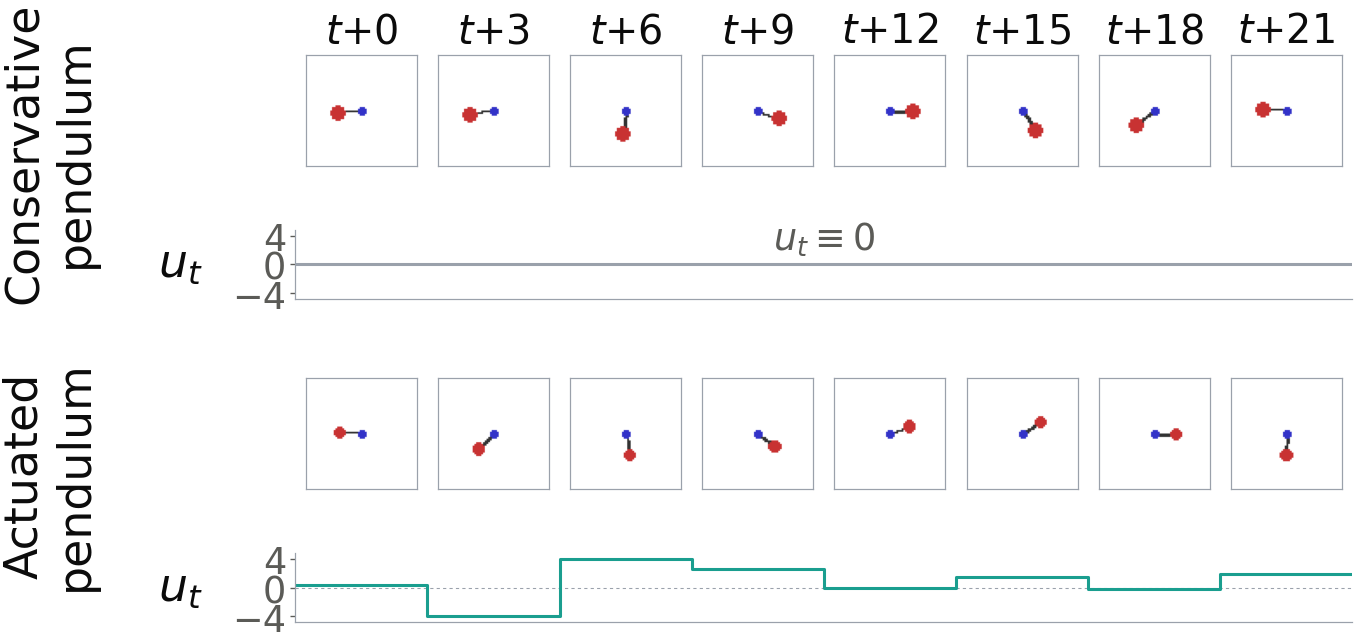

conservative episode 154, actuated episode 42, torque blocks [ 0.39 -3.96  3.95  2.51 -0.11  1.44 -0.19  1.96]


In [2]:
z = np.load(DSET / "strip_frames.npz")
INK, MUTED, FAINT, TEAL = "#0B0B0B", "#5B5B57", "#9AA1AB", "#1A9E8F"
stride, u_max, N = int(z["stride"]), float(z["u_max"]), len(z["frames_actuated"])
GAP = 0.16


def draw_block(fig, frames, u, y_img, h_img, y_act, h_act, x0, x1, label, actuated, times):
    t_end = N * stride
    tx = lambda t: x0 + (x1 - x0) * t / t_end
    for i, img in enumerate(frames):
        l, r = tx(i * stride + GAP / 2 * stride), tx((i + 1) * stride - GAP / 2 * stride)
        ax = fig.add_axes([l, y_img, r - l, h_img]); ax.imshow(img); thumbs(ax)
        if times:
            ax.set_title(f"$t{{+}}{i * stride}$", fontsize=26, color=INK, pad=8)
    fig.text(0.035, (y_act + y_img + h_img) / 2, label.replace(" ", "\n"), rotation=90,
             ha="center", va="center", fontsize=30, color=INK, linespacing=1.15)
    ax = fig.add_axes([tx(0), y_act, tx(t_end) - tx(0), h_act])
    kk = np.arange(N + 1) * stride
    ax.step(kk, np.append(u, u[-1]), where="post", color=TEAL if actuated else FAINT, lw=2.0)
    ax.axhline(0.0, color=FAINT, lw=0.7, ls=(0, (3, 3)), zorder=0)
    ax.set(xlim=(0, t_end), ylim=(-1.2 * u_max, 1.2 * u_max), xticks=[], yticks=[-4, 0, 4])
    ax.grid(False)
    ax.set_ylabel("$u_t$", fontsize=30, color=INK, rotation=0, labelpad=34, va="center")
    ax.tick_params(labelsize=24, colors=MUTED, length=3.0, pad=3)
    if not actuated:
        ax.text(0.5, 0.60, r"$u_t \equiv 0$", transform=ax.transAxes, ha="center",
                va="bottom", fontsize=24, color=MUTED)
    for s in ("left", "bottom"):
        ax.spines[s].set_edgecolor(FAINT); ax.spines[s].set_linewidth(0.8)


# Authored large and included at 0.8\linewidth; the type sizes are chosen for that scale.
fig = plt.figure(figsize=(12.4, 6.6))
draw_block(fig, z["frames_conservative"], np.zeros(N), 0.620, 0.290, 0.505, 0.095,
           0.215, 0.990, "Conservative pendulum", False, True)
draw_block(fig, z["frames_actuated"], z["u_blocks"], 0.175, 0.290, 0.060, 0.095,
           0.215, 0.990, "Actuated pendulum", True, False)
save(fig, "datasets", "datasets_strip_pendula")
plt.show()
print(f"conservative episode {int(z['episode_conservative'])}, actuated episode "
      f"{int(z['episode_actuated'])}, torque blocks {np.round(z['u_blocks'], 2)}")

### Fig. `rod-lengths` — the three rod lengths (Appendix)
One frame per length at the same angle ($\theta \approx 0.6$ rad), rendered to scale, so
the length is readable from a single frame.

wrote figures/datasets/dif_lengths_pendulum_appendix.png


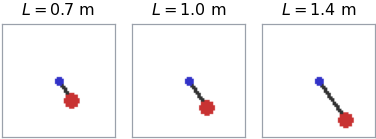

angles shown: [0.6 0.6 0.6] rad


In [3]:
z = np.load(DSET / "rod_length_frames.npz")
fig, axes = plt.subplots(1, 3, figsize=figsize(0.5, aspect=0.40))   # included at 0.5\linewidth
for ax, img, L, th in zip(axes, z["frames"], z["lengths"], z["theta"]):
    ax.imshow(img); thumbs(ax); ax.set_title(f"$L = {L:.1f}$ m")
fig.tight_layout()
save(fig, "datasets", "dif_lengths_pendulum", appendix=True)
plt.show()
print("angles shown:", np.round(z["theta"], 3), "rad")

### Fig. `pendulum-frames` — one episode of the single-rod pendulum (Appendix)
Fifteen evenly spaced frames of episode 0 of the single-rod dataset (`pendulum.h5`).

wrote figures/datasets/example_data_pendulum_appendix.png


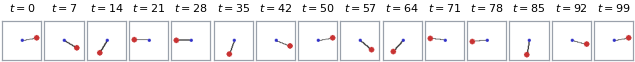

In [4]:
z = np.load(DSET / "single_rod_episode0_frames.npz")
fig, axes = plt.subplots(1, len(z["t"]), figsize=figsize(1.0, aspect=0.13))
for ax, img, t, th in zip(axes, z["frames"], z["t"], z["theta"]):
    ax.imshow(img); thumbs(ax)
    ax.set_title(f"$t={t}$", fontsize=LEGEND)
fig.subplots_adjust(wspace=0.08)
save(fig, "datasets", "example_data_pendulum", appendix=True)
plt.show()

### Tab. `datasets` — the two environments and their splits (Appendix)
Read from the split manifests; the design-cell counts come from the generators.

In [5]:
MAN = DSET / "manifests"
cons = json.loads((MAN / "split_pendulum_multi_v2_episode_srnn_K80_val.15_dt2_seed42.json").read_text())
act = json.loads((MAN / "split_pendulum_swingup_episode_srnn_K80_val.15_seed42.json").read_text())


def counts(m):
    tr, va, te = (len(m[f"{s}_episode_indices"]) for s in ("train", "val", "test"))
    assert not (set(m["train_episode_indices"]) & set(m["test_episode_indices"])), "split leak"
    assert not (set(m["val_episode_indices"]) & set(m["test_episode_indices"])), "split leak"
    return tr, va, te


(tc, vc, ec), (ta, va_, ea) = counts(cons), counts(act)
print(rf"episodes used                & {tc + vc + ec} & {ta + va_ + ea} \\")
print(rf"episodes                     & $\mathbf{{{tc} / {vc} / {ec}}}$ & "
      rf"$\mathbf{{{ta} / {va_} / {ea}}}$ \\")
print(rf"episodes per cell            & {(tc + vc + ec) // 3} & {(ta + va_ + ea) // 9} \\")
print(rf"train episodes per cell      & {tc // 3} & {ta // 9} \\")
print("\npaper: 300 / 900 episodes, 210/45/45 and 630/135/135, 100 per cell, 70 train per cell")
print("zero episode overlap between train, validation and test: verified by the asserts above")

episodes used                & 300 & 900 \\
episodes                     & $\mathbf{210 / 45 / 45}$ & $\mathbf{630 / 135 / 135}$ \\
episodes per cell            & 100 & 100 \\
train episodes per cell      & 70 & 70 \\

paper: 300 / 900 episodes, 210/45/45 and 630/135/135, 100 per cell, 70 train per cell
zero episode overlap between train, validation and test: verified by the asserts above


---
# 2. Conservative pendulum
Three rod lengths ($L \in \{0.7, 1.0, 1.4\}$ m), no actuation, $\Delta t = 0.1$ s
(`pendulum_multi_v2`). Arms: **LeHami** EXP-067 `a0m` and **LeWM** EXP-068 `b0m`, both with
a $W{=}1$ temporal ConvNet, three training seeds each. Rollout metrics are decoded by a
25-NN probe fitted on each model's own $K{=}1$ output and applied frozen.

### Fig. `cons-physics` — rollout error and latent volume (Experiments)
Left and middle: MAE of $\theta$ (wrapped) and $\omega$ over 45 test episodes; line = mean
over three seeds, band = $\pm 1$ s.d. across seeds. Right: cumulative log-volume
$\frac1n\sum_{i<K}\log|\det J(\mathbf z_i)|$ of the one-step map, where $J$ is taken with
respect to the newest input (for LeWM, $\partial\mathbf z_{t+1}/\partial\mathbf z_t$ with
the two older context embeddings held fixed); one seed, averaged over test episodes.
LeHami's $0$ holds by construction (exactly symplectic step).

wrote figures/conservative_pendulum/physics_rollout.png


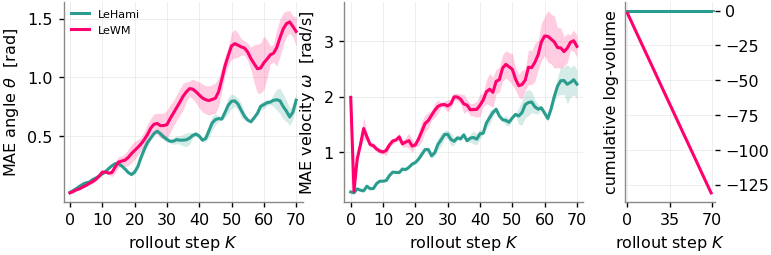

omega MAE ratio LeWM/LeHami, 3-seed mean: k=1..10 2.88x, k=70 1.31x   (text: 2.8x over the first ten steps, 1.5x at the end)


In [6]:
PM = CONS / "probe_metrics"
ARMS_C = {"hjepa": sorted(PM.glob("exp067_a0m_hjepa_w1_multi_s*.csv")),
          "lewm":  sorted(PM.glob("exp068_b0m_lewm_w1_multi_s*.csv"))}
VOL = pd.read_csv(CONS / "latent_volume" / "jacobian_rollout.csv")
VOL_ARM = {"hjepa": "a0m", "lewm": "b0m"}

fig, axes = plt.subplots(1, 3, figsize=(figsize()[0], figsize()[1] * 0.82),
                         gridspec_kw={"width_ratios": [0.16, 0.16, 0.06]})
fig.subplots_adjust(left=0.0, right=0.80, bottom=0.20, top=0.97, wspace=0.22)
for ax, var, unit in ((axes[0], "theta", "rad"), (axes[1], "omega", "rad/s")):
    for arm, files in ARMS_C.items():
        S = seed_curves(files, f"mae_{var}__knn_k1")
        mu, sd = S.mean(1), S.std(1, ddof=1)
        ax.fill_between(S.index, mu - sd, mu + sd, color=C[arm], alpha=0.20, lw=0)
        ax.plot(S.index, mu, color=C[arm], lw=2, label=NAME[arm])
    sym, word = (r"\theta", "angle") if var == "theta" else (r"\omega", "velocity")
    ax.set(xlabel="rollout step $K$", ylabel=rf"MAE {word} ${sym}$  [{unit}]",
           xlim=(-2, 72), xticks=range(0, 71, 10))
axes[0].set_yticks([0.5, 1.0, 1.5])
axes[0].legend()
ax = axes[2]
ax.yaxis.tick_right()
for arm, key in VOL_ARM.items():
    m = VOL[VOL.arm == key].groupby("k").logdet_per_dim_newest.mean()
    ax.plot(m.index, m.cumsum().values, color=C[arm], lw=2)
ax.axhline(0, color=C["control"], ls="--", lw=1.3, zorder=0)
ax.set(xlabel="rollout step $K$", ylabel="cumulative log-volume", xlim=(-2, 72),
       xticks=[0, 35, 70])
save(fig, "conservative_pendulum", "physics_rollout")
plt.show()

th = seed_curves(ARMS_C["hjepa"], "mae_omega__knn_k1"), seed_curves(ARMS_C["lewm"], "mae_omega__knn_k1")
r = th[1].mean(1) / th[0].mean(1)
print(f"omega MAE ratio LeWM/LeHami, 3-seed mean: k=1..10 {r.loc[1:10].mean():.2f}x, "
      f"k=70 {r.loc[70]:.2f}x   (text: 2.8x over the first ten steps, 1.5x at the end)")

### Tab. `cons-knnk1` — physics prediction by rollout band (Appendix)
25-NN probe fitted on each model's own $K{=}1$ output, averaged over each band.
**One seed** (`s0`) per arm, as in the paper; the 3-seed means are printed underneath.

In [7]:
BANDS = {"$k = 1$--$10$": (1, 10), "$k = 11$--$20$": (11, 20), "$k = 21$--$70$": (21, 70)}


def band_table(seeds):
    out = {}
    for var in ("theta", "omega"):
        for arm, files in ARMS_C.items():
            S = seed_curves([files[s] for s in seeds], f"mae_{var}__knn_k1").mean(1)
            out[(var, arm)] = {b: S.loc[lo:hi].mean() for b, (lo, hi) in BANDS.items()}
    return out


T = band_table([0])
for b in BANDS:
    cells = []
    for var in ("theta", "omega"):
        h, lw = T[(var, "hjepa")][b], T[(var, "lewm")][b]
        win = lw / h > 1
        f = (lambda v: rf"\textbf{{{v:.3f}}}") if win else (lambda v: f"{v:.3f}")
        ratio = rf"\textbf{{{lw / h:.2f}}}" if win else f"{lw / h:.2f}"
        cells += [f(h), f"{lw:.3f}", ratio]
    print(f"{b:<16} & " + " & ".join(cells) + r" \\")


def anchor(files, col):
    d = pd.read_csv(files[0]); return d[(d.split == "test") & (d.k == 0)][col].item()


print(rf"anchor R^2(omega), 25-NN on frozen encoder features: LeHami "
      rf"{anchor(ARMS_C['hjepa'], 'r2_omega__knn_gt'):+.3f}   LeWM "
      rf"{anchor(ARMS_C['lewm'], 'r2_omega__knn_gt'):+.3f}   (paper +0.975 / -0.667)")
print(rf"same anchor, LeHami ridge: {anchor(ARMS_C['hjepa'], 'r2_omega'):+.3f}   (paper +0.448)")

T3 = band_table([0, 1, 2])
print("\n3-seed means (not the paper's table):")
for b in BANDS:
    print(f"  {b:<16}" + "  ".join(f"{v}/{a}: {T3[(v, a)][b]:.3f}"
                                   for v in ("theta", "omega") for a in ("hjepa", "lewm")))

$k = 1$--$10$    & 0.107 & 0.100 & 0.93 & \textbf{0.364} & 1.020 & \textbf{2.80} \\
$k = 11$--$20$   & \textbf{0.225} & 0.287 & \textbf{1.27} & \textbf{0.669} & 1.169 & \textbf{1.75} \\
$k = 21$--$70$   & \textbf{0.596} & 0.981 & \textbf{1.65} & \textbf{1.534} & 2.331 & \textbf{1.52} \\
anchor R^2(omega), 25-NN on frozen encoder features: LeHami +0.975   LeWM -0.667   (paper +0.975 / -0.667)
same anchor, LeHami ridge: +0.448   (paper +0.448)

3-seed means (not the paper's table):
  $k = 1$--$10$   theta/hjepa: 0.106  theta/lewm: 0.095  omega/hjepa: 0.364  omega/lewm: 1.033
  $k = 11$--$20$  theta/hjepa: 0.221  theta/lewm: 0.270  omega/hjepa: 0.666  omega/lewm: 1.163
  $k = 21$--$70$  theta/hjepa: 0.604  theta/lewm: 0.962  omega/hjepa: 1.567  omega/lewm: 2.266


### Tab. `cons-latent-r2` — where the two blocks lose the reference (Appendix)
$R^2$ of LeHami's predicted $\mathbf q_k$, $\mathbf p_k$ against the encoded ground truth
at the same frame, test split, one seed (`exp067_a0m`).

In [8]:
r = pd.read_csv(CONS / "exp067_a0m" / "rollout_metrics.csv").query("split == 'test'").set_index("k")
KS = [0, 1, 5, 10, 20, 25, 50]
print("rollout step $k$ & " + " & ".join(map(str, KS)) + r" \\")
for col, lab in (("r2_q", "$R^2_q$ (position block)"), ("r2_p", "$R^2_p$ (momentum block)")):
    print(f"{lab} & " + " & ".join(f"${r.loc[k, col]:.3f}$" for k in KS) + r" \\")

rollout step $k$ & 0 & 1 & 5 & 10 & 20 & 25 & 50 \\
$R^2_q$ (position block) & $1.000$ & $0.997$ & $0.985$ & $0.950$ & $0.929$ & $0.646$ & $0.373$ \\
$R^2_p$ (momentum block) & $1.000$ & $0.935$ & $0.867$ & $0.613$ & $0.586$ & $-0.324$ & $-1.165$ \\


### Fig. `dt-reversal` — continuous time and reversibility (Experiments)
Left: LeHami (EXP-067, seed 0), trained at $\Delta t = 0.1$ s, integrated at step sizes
never seen in training; MAE of $\theta$ against a Runge–Kutta integration of the true ODE
(per episode, from that episode's own $g/L$). Right: relative round-trip error of the
latent state $\|(\mathbf q,\mathbf p)_{\rm back} - (\mathbf q,\mathbf p)_0\| / \|(\mathbf q,\mathbf p)_0\|$
after $K$ steps out and back with $\Delta t \to -\Delta t$ — an algebraic property of the
symmetric leapfrog, not a learned one.

wrote figures/conservative_pendulum/dt_and_reversal.png


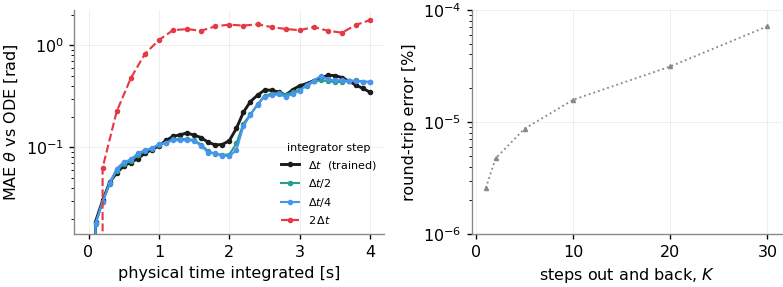

final MAE relative to the trained step: dt/2 1.270x, dt/4 1.250x, 2dt 5.11x
dt-flip round trip: max 7.1e-05 % over K <= 30   (physical p -> -p reversal, not plotted: 2.2 % at K=1, 23.5 % at K=30)


In [9]:
SCALES = {1.0: (r"$\Delta t$  (trained)", C["trained"]), 0.5: (r"$\Delta t / 2$", C["hjepa"]),
          0.25: (r"$\Delta t / 4$", "#4895EF"), 2.0: (r"$2\,\Delta t$", C["ablation"])}
dt = pd.read_csv(CONS / "exp067_a0m" / "physics_dt.csv")
rv = pd.read_csv(CONS / "exp067_a0m" / "physics_reversal.csv").sort_values("K")

fig, (ax0, ax1) = plt.subplots(1, 2, figsize=figsize())
for s, (lab, col) in SCALES.items():
    d = dt[dt.dt_scale == s].sort_values("t_sec")
    ax0.plot(d.t_sec, d.mae_theta_vs_ode, color=col, lw=1.9 if s == 1.0 else 1.4,
             ls="-" if s <= 1.0 else "--", marker="o", ms=2.6, label=lab)
ax0.set(xlabel="physical time integrated [s]", ylabel=r"MAE $\theta$ vs ODE [rad]", yscale="log")
ax0.legend(title="integrator step", title_fontsize=LEGEND, loc="lower right")
ax1.plot(rv.K, 100 * rv.roundtrip_rel_err_dtflip, color=C["control"], lw=1.2, ls=":",
         marker="^", ms=2.6)
ax1.set(xlabel="steps out and back, $K$", ylabel="round-trip error [%]", yscale="log",
        ylim=(1e-6, 1e-4))
fig.tight_layout()
save(fig, "conservative_pendulum", "dt_and_reversal")
plt.show()

fin = dt.sort_values("t_sec").groupby("dt_scale").tail(1).set_index("dt_scale").mae_theta_vs_ode
print(f"final MAE relative to the trained step: dt/2 {fin[0.5] / fin[1.0]:.3f}x, "
      f"dt/4 {fin[0.25] / fin[1.0]:.3f}x, 2dt {fin[2.0] / fin[1.0]:.2f}x")
print(f"dt-flip round trip: max {100 * rv.roundtrip_rel_err_dtflip.max():.1e} % over K <= {rv.K.max()}"
      f"   (physical p -> -p reversal, not plotted: {100 * rv.roundtrip_rel_err_pflip.iloc[0]:.1f} % at "
      f"K=1, {100 * rv.roundtrip_rel_err_pflip.iloc[-1]:.1f} % at K={rv.K.max()})")

### Tab. `exp096-isocompute` — accuracy at a fixed training budget (Appendix)
For each budget, the saved checkpoint (every 10 epochs) with the lowest
`validate/pred_loss` among those the budget allows; test MAE at $k{=}20$ through the frozen
25-NN probe; one seed per arm. Training FLOPs are measured on an L40S.

In [10]:
COST = pd.read_csv(CONS / "exp096" / "training_compute_l40s.csv").set_index("arm")
LOSS = pd.read_csv(CONS / "exp096" / "wandb_loss_history.csv")
PE = pd.read_csv(CONS / "exp096" / "probe_metrics_per_epoch.csv").query("split == 'test' and k == 20")
BUDGETS = [0.75, 1.5, 3.0, 6.0]
ARM_TEX = {"a0m": r"\algo~$W{=}1$", "b0m": r"LeWM $W{=}1$"}


def at_budget(arm, col, budget):
    cur = PE[PE.arm == arm].set_index("epoch")
    pflop = (cur.index + 1) * COST.loc[arm, "steps_per_epoch"] * COST.loc[arm, "gflops_per_step"] / 1e6
    vl = LOSS[LOSS.arm == arm].set_index("epoch").validate_pred_loss
    elig = [e for e, p in zip(cur.index, pflop) if p <= budget]
    ep = min(elig, key=lambda e: vl.loc[e])
    return cur.loc[ep, col], int(ep)


for col, lab in (("mae_theta__knn_k1", r"MAE $\theta$ [rad]"), ("mae_omega__knn_k1", r"MAE $\omega$ [rad/s]")):
    print(r"\midrule" + "\n" + rf"\multirow{{2}}{{*}}{{{lab}}}")
    best = {b: min(ARM_TEX, key=lambda a: at_budget(a, col, b)[0]) for b in BUDGETS}
    for a in ARM_TEX:
        cells = []
        for b in BUDGETS:
            v, ep = at_budget(a, col, b)
            cells.append(rf"$\mathbf{{{v:.3f}}}$ (ep {ep})" if best[b] == a else f"{v:.3f} (ep {ep})")
        print(f"  & {ARM_TEX[a]:<16} & " + " & ".join(cells) + r" \\")
print(f"\nPFLOP per 100 epochs: LeHami {COST.loc['a0m', 'tflops_100_epochs'] / 1e3:.1f}, "
      f"LeWM {COST.loc['b0m', 'tflops_100_epochs'] / 1e3:.1f};  GPU-h per 100 epochs: "
      f"{COST.loc['a0m', 'gpu_h_100_epochs']:.2f} / {COST.loc['b0m', 'gpu_h_100_epochs']:.2f}")

\midrule
\multirow{2}{*}{MAE $\theta$ [rad]}
  & \algo~$W{=}1$    & $\mathbf{0.283}$ (ep 9) & $\mathbf{0.207}$ (ep 19) & $\mathbf{0.252}$ (ep 39) & $\mathbf{0.222}$ (ep 79) \\
  & LeWM $W{=}1$     & 0.590 (ep 9) & 0.871 (ep 19) & 0.487 (ep 39) & 0.321 (ep 79) \\
\midrule
\multirow{2}{*}{MAE $\omega$ [rad/s]}
  & \algo~$W{=}1$    & $\mathbf{1.002}$ (ep 9) & $\mathbf{0.929}$ (ep 19) & $\mathbf{0.934}$ (ep 39) & $\mathbf{0.902}$ (ep 79) \\


  & LeWM $W{=}1$     & 1.625 (ep 9) & 2.146 (ep 19) & 1.620 (ep 39) & 1.270 (ep 79) \\

PFLOP per 100 epochs: LeHami 6.9, LeWM 6.1;  GPU-h per 100 epochs: 0.75 / 1.08


### Tab. `multi-params` — parameter counts (Appendix)
Measured from the checkpoints, in millions. The total also counts the action encoder.

In [11]:
ROWS = [("a0m", r"\algo~$W{=}1$ (EXP-067)"), ("b0m", r"LeWM $W{=}1$ (EXP-068)"),
        ("b1m", r"LeWM $W{=}3$ (EXP-066)")]
for a, lab in ROWS:
    c = COST.loc[a, [k for k in COST.columns if k.startswith("params_")]].astype(float) / 1e6
    pp = r"\textemdash" if c.params_pred_proj == 0 else f"{c.params_pred_proj:.3f}"
    print(f"{lab:<28} & {c.params_total:.2f} & {c.params_encoder:.3f} & "
          f"{c.params_predictor:.3f} & {c.params_projector:.3f} & {pp} \\\\")

\algo~$W{=}1$ (EXP-067)      & 3.03 & 0.315 & 2.234 & 0.465 & \textemdash \\
LeWM $W{=}1$ (EXP-068)       & 4.44 & 0.315 & 3.310 & 0.530 & 0.268 \\
LeWM $W{=}3$ (EXP-066)       & 4.45 & 0.318 & 3.310 & 0.530 & 0.268 \\


### Fig. `energy-projections` — one episode's encoder latents (Appendix)
**Single-rod pendulum** (`pendulum.h5`), LeHami EXP-027, episode 0. Left: the true phase
portrait $(\theta, \omega)$. Then the encoder's latents for the same frames: PC1 of
$\mathbf q$ against PC1 of $\mathbf p$, and the four latent dimensions with the largest
spread, each as $(q_i, p_i)$. Colour is the frame index; the circle marks the first frame
and the cross the last.

wrote figures/conservative_pendulum/energy_conservation_projections_appendix.png


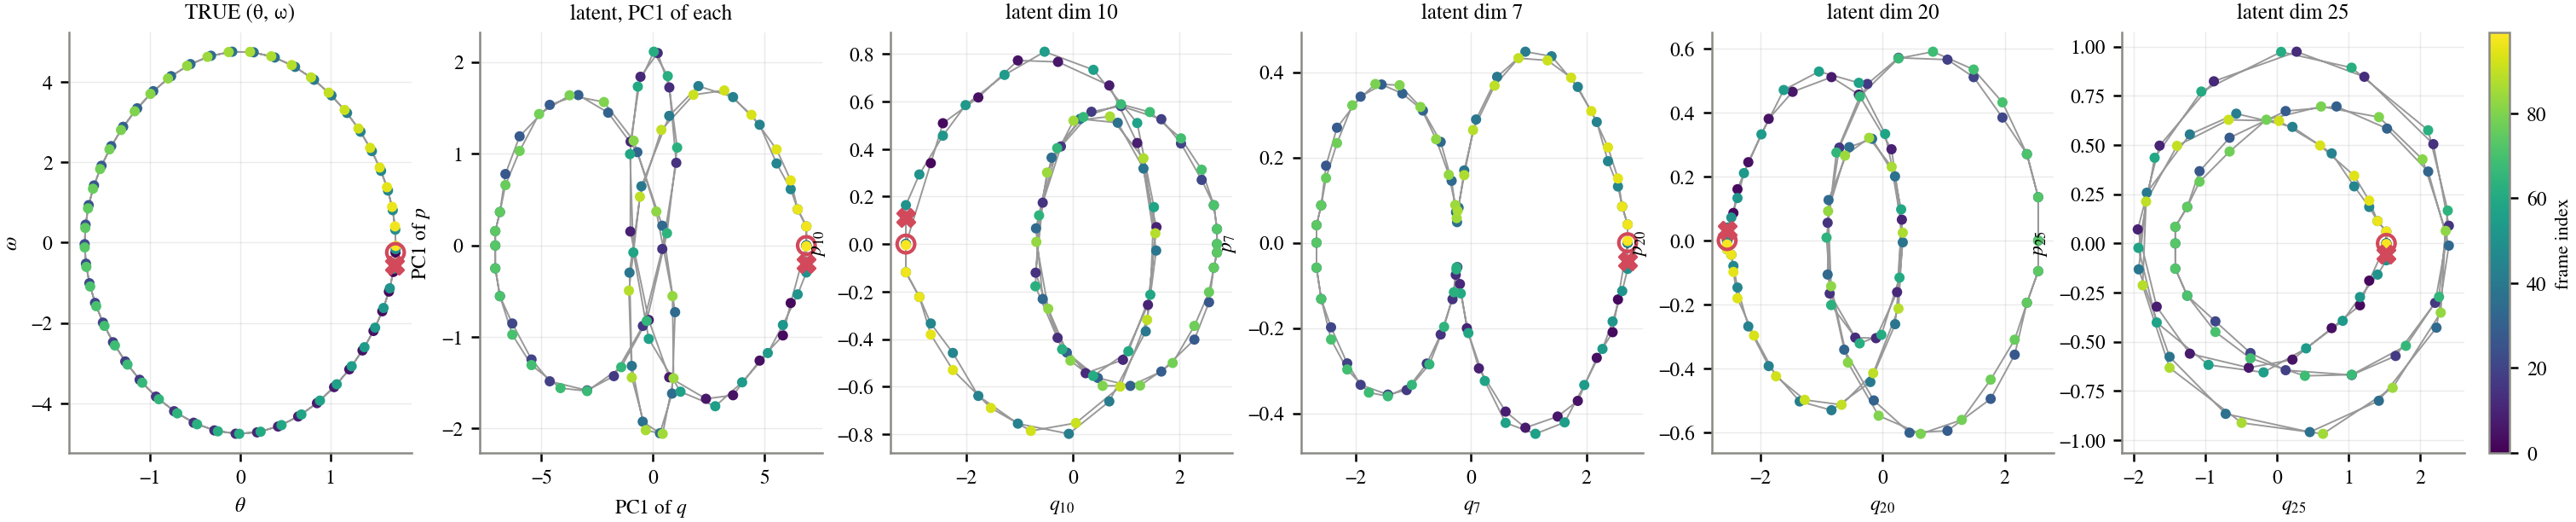

In [12]:
LZ = np.load(CONS / "latents_exp027_exp030.npz")      # episodes 0..59 of pendulum.h5
E_of = lambda S: 0.5 * S[:, 1] ** 2 - G * np.cos(S[:, 0])


def pc1(X):
    "First principal-component score of X, centred, sign-fixed (largest loading > 0)."
    mu, V = pc_basis(X, 1)
    return ((X - mu) @ V.T)[:, 0]


EP = 0
m0 = LZ["lehami_enc_ep"] == EP
q, p, states = LZ["lehami_enc_q"][m0], LZ["lehami_enc_p"][m0], LZ["lehami_enc_state"][m0]
t = np.arange(len(q))
dims = np.argsort(-(q.std(0) + p.std(0)))[:4]


def traj(ax, x, y, title, xl, yl):
    ax.plot(x, y, color="#999", lw=0.7, zorder=1)
    s = ax.scatter(x, y, c=t, cmap="viridis", s=11, zorder=2)
    ax.scatter(x[0], y[0], marker="o", s=55, facecolor="none", edgecolor="#d1495b", lw=1.5, zorder=3)
    ax.scatter(x[-1], y[-1], marker="X", s=55, color="#d1495b", zorder=3)
    ax.set_title(title, fontsize=9); ax.set_xlabel(xl); ax.set_ylabel(yl)
    return s


with mpl.rc_context(PAPER_RC):
    fig, axes = plt.subplots(1, 2 + len(dims), figsize=(3.1 * (2 + len(dims)), 3.2))
    traj(axes[0], states[:, 0], states[:, 1], "TRUE (θ, ω)", r"$\theta$", r"$\omega$")
    s = traj(axes[1], pc1(q), pc1(p), "latent, PC1 of each", "PC1 of $q$", "PC1 of $p$")
    for ax, j in zip(axes[2:], dims):
        traj(ax, q[:, j], p[:, j], f"latent dim {j}", f"$q_{{{j}}}$", f"$p_{{{j}}}$")
    fig.colorbar(s, ax=axes, fraction=0.015, pad=0.01).set_label("frame index", fontsize=8)
    save(fig, "conservative_pendulum", "energy_conservation_projections", appendix=True)
    plt.show()

### Fig. `latent_space_cons_pendulum` — rollouts against energy level sets (Appendix)
**Single-rod pendulum**, episodes 0–59 of `pendulum.h5`; four episodes spread over the
energy range are shown. Left: LeHami (EXP-027) rollout in (PC1 of $\mathbf q$, PC1 of
$\mathbf p$), height = learned $H_\phi$, with the plane at each episode's own $H_\phi$ at
$k{=}0$. Right: LeWM (EXP-030) rollout in (PC1, PC2) of the rolled-out $\mathbf z$, height =
physical energy read out of $\mathbf z$ by a ridge readout fitted once on encoded frames and
applied frozen; planes at each episode's true energy. Circles mark the anchor, crosses the
end of the rollout.

wrote figures/conservative_pendulum/paper_energy_level_sets_appendix.png


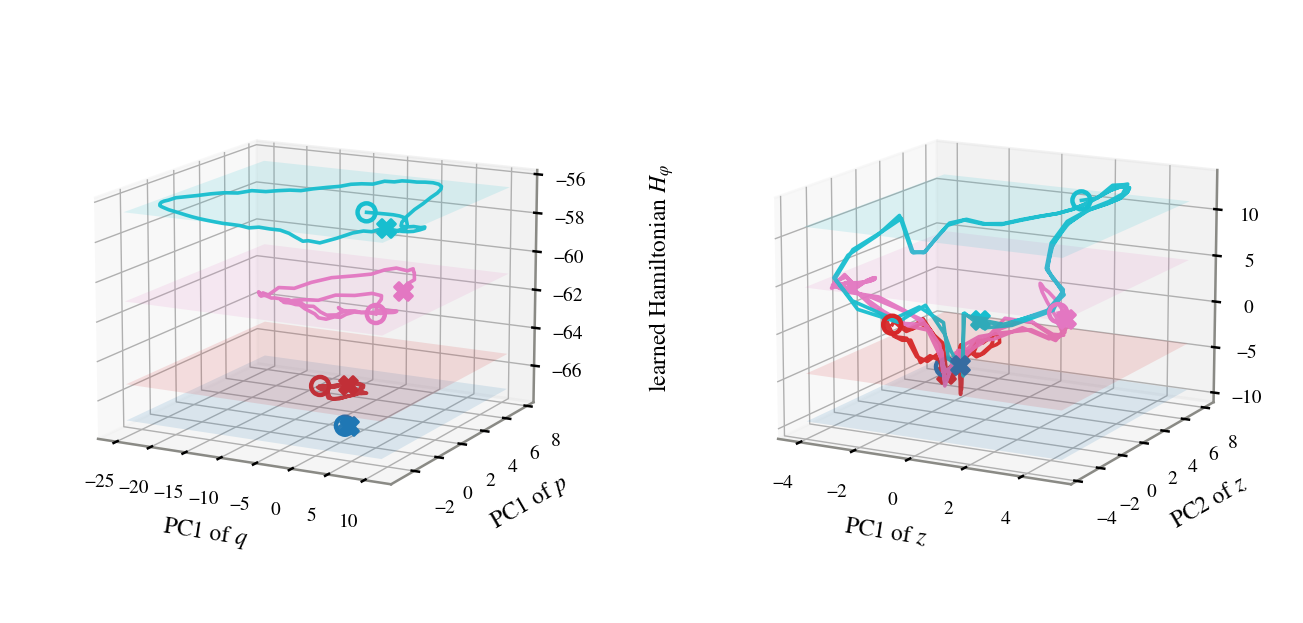

LeWM energy readout R^2 on encoded frames: 0.540
episodes shown (low to high energy): [(28, -9.45), (16, -4.36), (41, 4.73), (42, 11.05)]


In [13]:
QR, PR, HR = LZ["lehami_roll_q"], LZ["lehami_roll_p"], LZ["lehami_roll_H"]
ER, TR = LZ["lehami_roll_ep"], LZ["lehami_roll_state"]
ZR, ER_l, TR_l = LZ["lewm_roll_z"], LZ["lewm_roll_ep"], LZ["lewm_roll_state"]
x, y = pc1(QR), pc1(PR)
_mu, _V = pc_basis(ZR, 2)                    # PC1/PC2 of the ROLLED-OUT z
xl, yl = ((ZR - _mu) @ _V.T).T


def fit_readout(X, t, lam_rel=1e-6):
    "Ridge readout of the true energy from a latent, bias unpenalised. (apply_fn, R^2)"
    X = np.asarray(X, dtype=np.float64)
    A = np.c_[X, np.ones(len(X))]
    lam = lam_rel * np.trace(A.T @ A) / A.shape[1]
    R = np.eye(A.shape[1]); R[-1, -1] = 0.0
    b = np.linalg.solve(A.T @ A + lam * R, A.T @ t)
    r2 = 1 - ((t - A @ b) ** 2).sum() / ((t - t.mean()) ** 2).sum()
    return (lambda Y: np.c_[np.asarray(Y, dtype=np.float64), np.ones(len(Y))] @ b), float(r2)


# fitted ONCE on encoded frames, applied frozen along LeWM's own rollout
readout_l, r2_l = fit_readout(LZ["lewm_enc_z"], E_of(LZ["lewm_enc_state"]))
El_hat = readout_l(ZR)
E_true_h = E_of(TR)

SHOW = 4
common = np.intersect1d(np.unique(ER), np.unique(ER_l))
epE = {e: float(E_true_h[ER == e].mean()) for e in common}
order = sorted(common, key=lambda e: epE[e])
sel = [order[i] for i in np.linspace(0, len(order) - 1, SHOW).round().astype(int)]
cols = plt.cm.tab10(np.linspace(0, 0.9, len(sel)))

PANELS = [(x,  y,  HR,     ER,   None, "PC1 of $q$", "PC1 of $p$",
           r"learned Hamiltonian $H_\varphi$"),
          (xl, yl, El_hat, ER_l, epE,  "PC1 of $z$", "PC2 of $z$",
           r"physical energy $E$")]

with mpl.rc_context(PAPER_RC):
    fig = plt.figure(figsize=figsize(1.0, 5.3 / 11.6))
    for i, (X, Y, Zv, ep, planes, xlab, ylab, zlab) in enumerate(PANELS, start=1):
        ax = fig.add_subplot(1, 2, i, projection="3d")
        m_all = np.isin(ep, sel)
        GX, GY = np.meshgrid(np.linspace(X[m_all].min(), X[m_all].max(), 2),
                             np.linspace(Y[m_all].min(), Y[m_all].max(), 2))
        for c, e in zip(cols, sel):
            m = ep == e
            # LeHami's plane is its own k=0 value of H_phi; LeWM's is the TRUE energy
            lvl = planes[e] if planes is not None else float(Zv[m][0])
            ax.plot_surface(GX, GY, np.full_like(GX, lvl), color=c, alpha=0.13,
                            shade=False, linewidth=0, zorder=1)
            ax.plot(X[m], Y[m], Zv[m], color=c, lw=1.3, alpha=0.95, zorder=4,
                    label=f"ep {int(e)}")
            ax.scatter(X[m][0], Y[m][0], Zv[m][0], marker="o", s=42, facecolor="none",
                       edgecolor=c, lw=1.6, zorder=5)
            ax.scatter(X[m][-1], Y[m][-1], Zv[m][-1], marker="X", s=42, color=c, zorder=5)
        ax.set_xlabel(xlab); ax.set_ylabel(ylab)
        ax.zaxis.set_rotate_label(False)
        ax.set_zlabel(zlab, rotation=90, labelpad=14)
        ax.view_init(elev=14, azim=-62); ax.tick_params(labelsize=7)
        ax.tick_params(axis="z", pad=1)
        ax.set_box_aspect(None, zoom=0.82)
    fig.subplots_adjust(left=0.075, right=0.985, bottom=0.06, top=0.97, wspace=0.02)
    save(fig, "conservative_pendulum", "paper_energy_level_sets", appendix=True)
    plt.show()
print(f"LeWM energy readout R^2 on encoded frames: {r2_l:.3f}")
print("episodes shown (low to high energy):", [(int(e), round(epE[e], 2)) for e in sel])

### Fig. `physics_vs_lehami_cons_pendulum` — true energy against learned $H_\phi$ (Appendix)
**Single-rod pendulum**, episodes 0–59. Left: the true phase space, one ring per episode at
its conserved energy. Right: LeHami's own rollout from each anchor, in (PC1 of $\mathbf q$,
PC1 of $\mathbf p$), height and colour = learned $H_\phi$.

wrote figures/conservative_pendulum/physical_vs_lehami_appendix.png


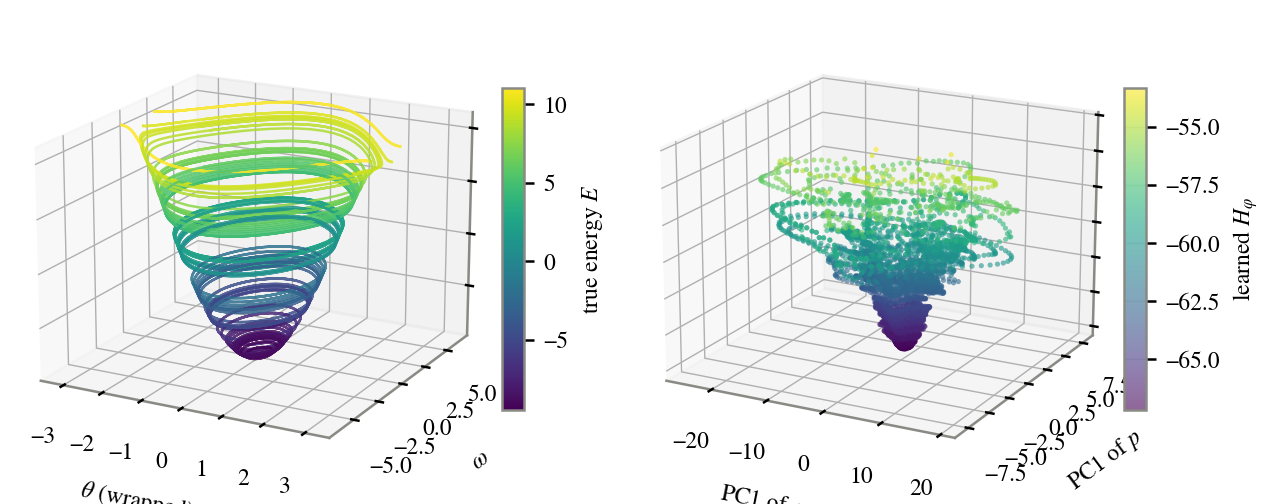

In [14]:
theta_w = np.arctan2(np.sin(TR[:, 0]), np.cos(TR[:, 0]))
omega = TR[:, 1]
EPS = np.unique(ER)
ep_E = {e: float((0.5 * TR[ER == e, 1] ** 2 - G * np.cos(TR[ER == e, 0])).mean()) for e in EPS}
norm = plt.Normalize(min(ep_E.values()), max(ep_E.values()))

with mpl.rc_context(PAPER_RC):
    fig = plt.figure(figsize=figsize(1.0, 5.4 / 12.4))
    # left: TRUE phase space, stacked by the conserved energy
    ax1 = fig.add_subplot(121, projection="3d")
    for e in EPS:
        m = ER == e
        th, om = theta_w[m].copy(), omega[m].copy()
        brk = np.where(np.abs(np.diff(th)) > np.pi)[0] + 1      # break at the +-pi seam
        th, om = np.insert(th, brk, np.nan), np.insert(om, brk, np.nan)
        ax1.plot(th, om, np.full(len(th), ep_E[e]),
                 lw=0.9, alpha=0.85, color=plt.cm.viridis(norm(ep_E[e])))
    ax1.set_xlabel(r"$\theta$ (wrapped)"); ax1.set_ylabel(r"$\omega$")
    sm = plt.cm.ScalarMappable(norm=norm, cmap="viridis"); sm.set_array([])
    ax1.set_zticklabels([])
    cax = fig.add_axes([0.47, 0.25, 0.015, 0.5])
    fig.colorbar(sm, cax=cax).set_label(r"true energy $E$")
    # right: the model's own rollout, learned Hamiltonian as height and colour
    ax2 = fig.add_subplot(122, projection="3d")
    s = ax2.scatter(x, y, HR, c=HR, cmap="viridis", s=3.5, alpha=0.6,
                    linewidths=0, depthshade=False)
    ax2.set_xlabel("PC1 of $q$"); ax2.set_ylabel("PC1 of $p$")
    cax = fig.add_axes([0.89, 0.25, 0.015, 0.5])
    ax2.set_zticklabels([])
    fig.colorbar(s, cax=cax).set_label(r"learned $H_\varphi$")
    for a in (ax1, ax2):
        a.view_init(elev=18, azim=-62)
    save(fig, "conservative_pendulum", "physical_vs_lehami", appendix=True)
    plt.show()

### Fig. `dino-powered` — frozen DINOv2 encoder (Appendix)
DINO-LeHami (EXP-098 `a0d`) against DINO-WM (EXP-098 `b0d`), both at the matched epoch 60,
same loss, probe and evaluation as Fig. `cons-physics`. Conservative pendulum at
$\Delta t = 0.05$ s; one seed each.

wrote figures/conservative_pendulum/dino_physics_rollout_appendix.png


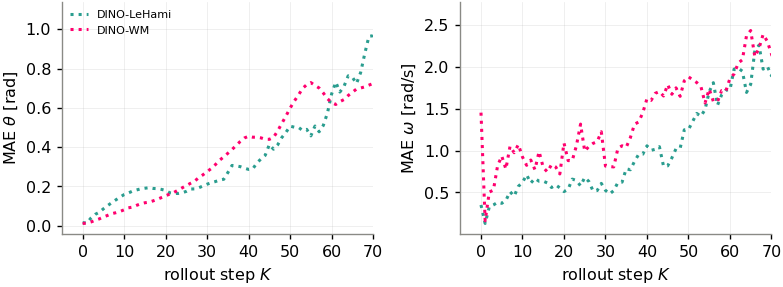

In [15]:
fig, axes = plt.subplots(1, 2, figsize=figsize())
for label, stem, arm in (("DINO-LeHami", "exp098_a0d_ep059", "hjepa"), ("DINO-WM", "exp098_b0d_ep059", "lewm")):
    d = pd.read_csv(CONS / "dino" / f"{stem}.csv").query("split == 'test'").sort_values("k")
    for ax, var in zip(axes, ("theta", "omega")):
        ax.plot(d.k, d[f"mae_{var}__knn_k1"], color=C[arm], ls=":", lw=2, label=label)
for ax, (var, unit) in zip(axes, ((r"\theta", "rad"), (r"\omega", "rad/s"))):
    ax.set(xlabel="rollout step $K$", ylabel=f"MAE ${var}$ [{unit}]", xlim=(-5, 70),
           xticks=range(0, 71, 10))
axes[0].legend()
fig.tight_layout()
save(fig, "conservative_pendulum", "dino_physics_rollout", appendix=True)
plt.show()

### Fig. `jacobian-volume` — both volume measures, per state (Appendix)
One Jacobian per test episode at the anchor (45 states; bar = mean). Left: the full map,
$n=64$ for LeHami on $(\mathbf q,\mathbf p)$ and $n=192$ for LeWM on its three-embedding
context. Right: the newest block $\partial\mathbf z_{t+1}/\partial\mathbf z_t$, $n=64$ for
both. Dashed = the true flow. One seed per model.

wrote figures/conservative_pendulum/jacobian_volume_k0_appendix.png


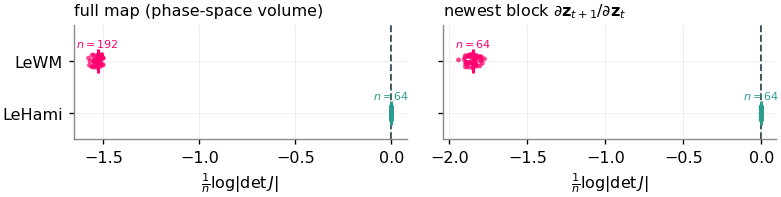

In [16]:
K0 = pd.read_csv(CONS / "latent_volume" / "jacobian_k0.csv")
rng = np.random.default_rng(0)
fig, axes = plt.subplots(1, 2, figsize=figsize(1.0, aspect=0.28), sharey=True)
for ax, col, ncol, title in ((axes[0], "logdet_per_dim_full", "n_full", "full map (phase-space volume)"),
                             (axes[1], "logdet_per_dim_newest", "n_new",
                              r"newest block $\partial \mathbf{z}_{t+1} / \partial \mathbf{z}_t$")):
    for y, (key, arm) in enumerate((("a0m", "hjepa"), ("b0m", "lewm"))):
        d = K0[K0.arm == key]; v = d[col].to_numpy()
        ax.scatter(v, y + rng.uniform(-0.13, 0.13, len(v)), s=10, alpha=0.75, color=C[arm], edgecolor="none")
        ax.plot([v.mean()], [y], marker="|", ms=16, mew=2.0, color=C[arm])
        ax.annotate(rf"$n={int(d[ncol].iloc[0])}$", (v.mean(), y + 0.22), ha="center",
                    va="bottom", fontsize=LEGEND, color=C[arm])
    ax.axvline(0, color="#264653", ls="--", lw=1.2, zorder=0)
    ax.set(yticks=[0, 1], ylim=(-0.5, 1.7), xlabel=r"$\frac{1}{n}\log|\det J|$")
    ax.set_yticklabels([NAME["hjepa"], NAME["lewm"]])
    ax.set_title(title, loc="left")
fig.tight_layout()
save(fig, "conservative_pendulum", "jacobian_volume_k0", appendix=True)
plt.show()

### Tab. `jacobian-volume` — volume and conditioning of the one-step map (Appendix)
Per-dimension $\frac1n\log|\det J|$ averaged over every rollout step of 45 test episodes
(70 steps conservative, 76 actuated at the true per-step torque). Annihilated directions
($\sigma_i < 10^{-6}\sigma_{\max}$) and condition number are for the full map. One seed.

In [17]:
RA = pd.read_csv(ACT / "latent_volume" / "jacobian_rollout_actuated.csv")
cols4 = [(VOL, "a0m"), (VOL, "b0m"), (RA, "a0q"), (RA, "b0s")]


def cell(df, arm, col, fmt):
    return fmt.format(df[df.arm == arm][col].mean())


for lab, col, fmt in ((r"$\frac{1}{n}\log|\det J|$, full map", "logdet_per_dim_full", "${:.2f}$"),
                      (r"$\frac{1}{n}\log|\det J|$, newest block", "logdet_per_dim_newest", "${:.2f}$"),
                      ("annihilated directions per step", "n_crushed", "${:.1f}$"),
                      (r"$\log_{10}$ condition number", "log10_cond", "${:.2f}$")):
    print(f"{lab:<40} & " + " & ".join(cell(d, a, col, fmt) for d, a in cols4) + r" \\")

$\frac{1}{n}\log|\det J|$, full map      & $0.00$ & $-1.54$ & $0.00$ & $-1.60$ \\
$\frac{1}{n}\log|\det J|$, newest block  & $0.00$ & $-1.87$ & $0.00$ & $-1.91$ \\
annihilated directions per step          & $0.0$ & $2.0$ & $0.0$ & $2.0$ \\
$\log_{10}$ condition number             & $0.41$ & $9.64$ & $0.33$ & $9.70$ \\


---
# 3. Actuated pendulum
Swing-up dataset (`pendulum_swingup`): three rod lengths $\times$ three masses, torque drawn
uniformly and held for three frames. Arms: **LeHami** EXP-079 `a0q` ($W{=}1$, SIGReg on
$\mathbf q$), **LeWM** $W{=}1$ EXP-072 `b0s`, LeWM $W{=}3$ tied EXP-076 `b3s` and untied
EXP-099 `b3f`; three seeds each, 135 test episodes.

### Tab. `physics_prediction_anchor` — physics prediction at the anchor (Experiments)
Three probe tiers on the frozen encoder features ($K{=}0$), test split, mean $\pm$ s.d. over
three seeds. MAE $\theta$ in units of $10^{-2}$ rad. Bold = the better model within a tier.

In [18]:
CAP = pd.read_csv(ACT / "capacity_probes.csv").query("split == 'test' and k == 0").copy()
CAP["arm"] = CAP.exp.str.replace(r"_s\d$", "", regex=True)
CAP["mae_theta_crad"] = 100 * CAP.mae_theta_rad
AGG = CAP.groupby(["arm", "probe"])[["mae_theta_crad", "mae_theta_deg", "mae_omega", "r2_omega"]].agg(["mean", "std"])
TIERS = (("ridge", "ridge"), ("knn25", "25-NN"), ("mlp", "MLP"))


def mtex(arm, probe, col, fmt, bold):
    m, s = AGG.loc[(arm, probe), (col, "mean")], AGG.loc[(arm, probe), (col, "std")]
    body = f"{m:{fmt}} \\pm {s:{fmt.lstrip('+')}}"
    return rf"$\mathbf{{{body}}}$" if bold else f"${body}$"


def anchor_table(arms, cols):
    "cols: (column, format, higher_is_better)"
    for arm, name in arms:
        print(rf"\multirow{{3}}{{*}}{{{name}}}")
        for probe, pname in TIERS:
            cells = []
            for col, fmt, hib in cols:
                vals = {a: AGG.loc[(a, probe), (col, "mean")] for a, _ in arms}
                best = (max if hib else min)(vals, key=vals.get)
                cells.append(mtex(arm, probe, col, fmt, best == arm))
            print(f"  & {pname} & " + " & ".join(cells) + r" \\")
        print(r"\midrule")


anchor_table([("exp079_a0q_hjepa", r"\algo"), ("exp072_b0s_lewm", "LeWM")],
             [("mae_theta_crad", ".1f", False), ("mae_omega", ".3f", False), ("r2_omega", "+.3f", True)])

\multirow{3}{*}{\algo}
  & ridge & $23.0 \pm 2.0$ & $\mathbf{1.168 \pm 0.001}$ & $\mathbf{+0.491 \pm 0.005}$ \\
  & 25-NN & $6.8 \pm 1.8$ & $\mathbf{0.419 \pm 0.045}$ & $\mathbf{+0.889 \pm 0.024}$ \\
  & MLP & $3.0 \pm 0.4$ & $\mathbf{0.184 \pm 0.019}$ & $\mathbf{+0.987 \pm 0.004}$ \\
\midrule
\multirow{3}{*}{LeWM}
  & ridge & $\mathbf{1.4 \pm 0.1}$ & $2.422 \pm 0.001$ & $-0.014 \pm 0.001$ \\
  & 25-NN & $\mathbf{1.1 \pm 0.0}$ & $2.508 \pm 0.002$ & $-0.103 \pm 0.001$ \\
  & MLP & $\mathbf{1.9 \pm 0.1}$ & $2.419 \pm 0.001$ & $-0.011 \pm 0.001$ \\
\midrule


### Tab. `capacity` — the same probes with a $W{=}3$ encoder (Appendix)
LeHami EXP-082 (stencil $\mathbf p$, separate SIGReg statistics on $\mathbf q$ and $\mathbf p$)
against LeWM EXP-076. MAE $\theta$ in degrees, as in the paper.

In [19]:
anchor_table([("exp082_a3p_hjepa", r"\algo, stencil $p$ (EXP-082)"), ("exp076_b3s_lewm", "LeWM (EXP-076)")],
             [("mae_theta_deg", ".2f", False), ("r2_omega", "+.3f", True)])

\multirow{3}{*}{\algo, stencil $p$ (EXP-082)}
  & ridge & $12.19 \pm 0.53$ & $\mathbf{+0.527 \pm 0.010}$ \\
  & 25-NN & $2.46 \pm 0.16$ & $\mathbf{+0.892 \pm 0.005}$ \\
  & MLP & $\mathbf{1.81 \pm 0.13}$ & $\mathbf{+0.993 \pm 0.001}$ \\
\midrule
\multirow{3}{*}{LeWM (EXP-076)}
  & ridge & $\mathbf{6.43 \pm 0.26}$ & $-0.032 \pm 0.003$ \\
  & 25-NN & $\mathbf{1.47 \pm 0.06}$ & $-0.374 \pm 0.016$ \\
  & MLP & $2.24 \pm 0.21$ & $-0.091 \pm 0.005$ \\
\midrule


### Fig. `actuated_pendulum_physics` — rollout error, $W{=}1$ and $W{=}3$ (Appendix)
25-NN probe fitted at $K{=}1$ and applied frozen; line = mean over three seeds, band =
$\pm 1$ s.d. across seeds. LeWM $W{=}1$ and $W{=}3$ share a colour family and differ in
linestyle.

wrote figures/actuated_pendulum/rollout_lehami_vs_lewm_w1_w3_appendix.png


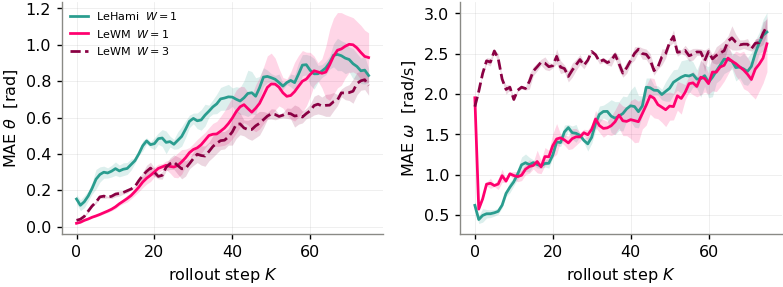

In [20]:
APM = ACT / "probe_metrics"
ARMS_A = [(rf"{NAME['hjepa']}  $W{{=}}1$", "exp079_a0q_hjepa", C["hjepa"], LS[1]),
          (rf"{NAME['lewm']}  $W{{=}}1$", "exp072_b0s_lewm", C["lewm"], LS[1]),
          (rf"{NAME['lewm']}  $W{{=}}3$", "exp076_b3s_lewm", C["lewm_w3"], LS[3])]
KMAX = min(pd.read_csv(APM / f"{s}_s0.csv").k.max() for _, s, _, _ in ARMS_A)
fig, axes = plt.subplots(1, 2, figsize=figsize())
for ax, col, ylab in ((axes[0], "mae_theta__knn_k1", r"MAE $\theta$  [rad]"),
                      (axes[1], "mae_omega__knn_k1", r"MAE $\omega$  [rad/s]")):
    for label, stem, colour, ls in ARMS_A:
        S = seed_curves(sorted(APM.glob(f"{stem}_s*.csv")), col).loc[:KMAX]
        mu, sd = S.mean(1), S.std(1, ddof=1)
        ax.fill_between(S.index, mu - sd, mu + sd, color=colour, alpha=0.16, lw=0)
        ax.plot(S.index, mu, color=colour, ls=ls, lw=1.8, label=label)
    ax.set(xlabel="rollout step $K$", ylabel=ylab)
axes[0].legend()
fig.tight_layout()
save(fig, "actuated_pendulum", "rollout_lehami_vs_lewm_w1_w3", appendix=True)
plt.show()

### Fig. `canonical_actuated_pendulum` — is the $(\mathbf q,\mathbf p)$ split canonical? (Appendix)
$R^2$ of $\theta$ (as $\sin\theta,\cos\theta$) and $\omega$ decoded from each half of the
frozen encoder output at the anchor, 25-NN under five episode-grouped folds, pooled
out-of-fold; test episodes; mean $\pm$ s.d. over three seeds. LeWM has no momentum block and
is scored on its whole embedding $\mathbf z$.

wrote figures/actuated_pendulum/canonicality_lehami_vs_lewm_w1_w3_appendix.png


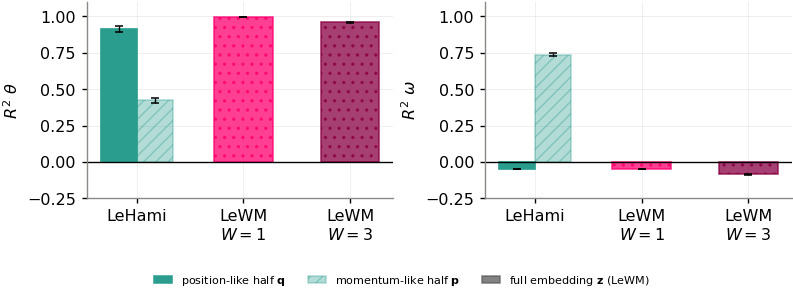

                               mean    std
arm              half target              
exp072_b0s_lewm  z    omega  -0.050  0.000
                      theta   0.999  0.000
exp076_b3s_lewm  z    omega  -0.084  0.003
                      theta   0.959  0.002
exp079_a0q_hjepa p    omega   0.737  0.011
                      theta   0.423  0.015
                 q    omega  -0.046  0.000
                      theta   0.913  0.018


In [21]:
from sklearn.model_selection import GroupKFold
from sklearn.neighbors import KNeighborsRegressor


def grouped_r2(X, Y, groups, n_neighbors=25, folds=5):
    "Pooled out-of-fold 1 - SSE/SST, folds grouped by episode, train-mean floor."
    Y = Y if Y.ndim > 1 else Y.reshape(-1, 1)
    num = den = 0.0
    for tr, te in GroupKFold(folds).split(X, Y, groups):
        mu, sd = X[tr].mean(0), X[tr].std(0)
        sd = np.maximum(sd, 1e-3 * sd.max())
        pr = KNeighborsRegressor(n_neighbors).fit((X[tr] - mu) / sd, Y[tr]).predict((X[te] - mu) / sd)
        num += ((pr.reshape(Y[te].shape) - Y[te]) ** 2).sum()
        den += ((Y[te] - Y[tr].mean(0)) ** 2).sum()
    return 1.0 - num / den


PF = ACT / "probe_features_k0"
ARMS_CAN = [("exp079_a0q_hjepa", "LeHami", C["hjepa"]), ("exp072_b0s_lewm", "LeWM\n$W=1$", C["lewm"]),
            ("exp076_b3s_lewm", "LeWM\n$W=3$", C["lewm_w3"])]
rows = []
for stem, _, _ in ARMS_CAN:
    for s in range(3):
        z = np.load(PF / f"{stem}_s{s}.npz")
        X, Y = z["X_test_k0"].astype(float), z["Y_test_k0"].astype(float)
        cols, d, n_ep = [str(c) for c in z["y_cols"]], int(z["latent_dim"]), int(z["n_test_episodes"])
        groups = np.repeat(np.arange(n_ep), X.shape[0] // n_ep)
        halves = {"q": X[:, :d], "p": X[:, d:]} if bool(z["uses_p"]) else {"z": X}
        tg = {"theta": Y[:, [cols.index("sin_theta"), cols.index("cos_theta")]], "omega": Y[:, cols.index("omega")]}
        for h, Xh in halves.items():
            for t, Yt in tg.items():
                rows.append(dict(arm=stem, seed=s, half=h, target=t, r2=grouped_r2(Xh, Yt, groups)))
CAN = pd.DataFrame(rows).groupby(["arm", "half", "target"]).r2.agg(["mean", "std"])

W = 0.34
green, grey = C["hjepa"], "#5A5A5A"
fig, axes = plt.subplots(1, 2, figsize=figsize(1.0, aspect=0.36))
for ax, target, ylab in ((axes[0], "theta", r"$R^2\ \theta$"), (axes[1], "omega", r"$R^2\ \omega$")):
    for i, (stem, _, colour) in enumerate(ARMS_CAN):
        bars = ([("q", -W / 2, W, 1.0, None), ("p", W / 2, W, 0.35, "///")]
                if (stem, "p", target) in CAN.index else [("z", 0.0, 0.55, 0.75, "..")])
        for h, dx, w, alpha, hatch in bars:
            m, sd = CAN.loc[(stem, h, target)]
            ax.bar(i + dx, m, width=w, yerr=sd, capsize=2.5, color=colour, edgecolor=colour,
                   lw=1.1, alpha=alpha, hatch=hatch, error_kw=dict(lw=0.9))
    ax.axhline(0, color="k", lw=0.9)
    ax.set(xticks=range(len(ARMS_CAN)), ylim=(-0.25, 1.1), ylabel=ylab)
    ax.set_xticklabels([n for _, n, _ in ARMS_CAN])
handles = [plt.Rectangle((0, 0), 1, 1, facecolor=green, edgecolor=green),
           plt.Rectangle((0, 0), 1, 1, facecolor=green, edgecolor=green, alpha=0.35, hatch="///"),
           plt.Rectangle((0, 0), 1, 1, facecolor=grey, edgecolor=grey, alpha=0.75, hatch="..")]
fig.legend(handles, [r"position-like half $\mathbf{q}$", r"momentum-like half $\mathbf{p}$",
                     r"full embedding $\mathbf{z}$ (LeWM)"], loc="lower center", ncol=3,
           bbox_to_anchor=(0.5, -0.06))
fig.tight_layout(rect=(0, 0.06, 1, 1))
save(fig, "actuated_pendulum", "canonicality_lehami_vs_lewm_w1_w3", appendix=True)
plt.show()
print(CAN.round(3).to_string())

### Tab. `sign-blind` — the encoder window and the sign of $\omega$ (Appendix)
25-NN fitted on 12k rows of the training anchors (the subsample is stored exactly),
evaluated on the test anchors, predicting $\omega$ and $|\omega|$; mean over three seeds.
A time-symmetric (tied) $W{=}3$ kernel sees the speed but not its sign.

In [22]:
from sklearn.metrics import r2_score

for stem, name in (("exp072_b0s_lewm", r"LeWM $W{=}1$"), ("exp076_b3s_lewm", r"LeWM $W{=}3$")):
    r = []
    for s in range(3):
        z = np.load(PF / f"{stem}_s{s}.npz")
        iw = [str(c) for c in z["y_cols"]].index("omega")
        Xtr, Ytr, Xte, Yte = z["X_train_k0_sub12k"], z["Y_train_k0_sub12k"], z["X_test_k0"], z["Y_test_k0"]
        pair = []
        for fn in (lambda y: y[:, iw], lambda y: np.abs(y[:, iw])):
            m = KNeighborsRegressor(n_neighbors=25).fit(Xtr, fn(Ytr))
            pair.append(r2_score(fn(Yte), m.predict(Xte)))
        r.append(pair)
    r = np.array(r)
    print(f"{name:<14} & 3 & ${r[:, 0].mean():+.3f}$ & ${r[:, 1].mean():+.3f}$ & "
          f"${(r[:, 1] - r[:, 0]).mean():+.3f}$ \\\\")

LeWM $W{=}1$   & 3 & $-0.048$ & $+0.032$ & $+0.080$ \\


LeWM $W{=}3$   & 3 & $-0.115$ & $+0.921$ & $+1.036$ \\


### Tab. `episode-variance` — within- vs between-episode variance, by SIGReg placement (Appendix)
Encoder latents at every rollout step of the test episodes. Per latent dimension,
$V_\text{within}$ is the mean squared deviation about the episode's own mean and
$V_\text{between}$ the variance of those means; reported
$100\,V_\text{within}/(V_\text{within}+V_\text{between})$ for $\mathbf q$, mean $\pm$ s.d. over
three seeds, and $\mathrm{std} = \sqrt{V_\text{within}+V_\text{between}}$.

In [23]:
EL = ACT / "encoder_latents"
GRID = {1: [("exp071_a0s_hjepa", "joint"), ("exp079_a0q_hjepa", "q"), ("exp080_a0p_hjepa", "split")],
        3: [("exp075_a3s_hjepa", "joint"), ("exp081_a3q_hjepa", "q"), ("exp082_a3p_hjepa", "split")]}
KCOM = min(int(np.load(f)["ks"].max()) for f in EL.glob("*.npz"))


def split_var(x):
    mu = x.mean(0)
    return float(((x - mu[None]) ** 2).mean((0, 1)).mean()), float(mu.var(0).mean())


for w, arms in GRID.items():
    stats = {}
    for stem, mode in arms:
        rec = []
        for s in range(3):
            z = np.load(EL / f"{stem}_s{s}.npz")
            keep = z["ks"] <= KCOM
            wq, bq = split_var(z["gt_q"][keep].astype(float)); wp, bp = split_var(z["gt_p"][keep].astype(float))
            rec.append((100 * wq / (wq + bq), np.sqrt(wq + bq), np.sqrt(wp + bp)))
        stats[mode] = np.array(rec)
    best = max(stats, key=lambda m: stats[m][:, 0].mean())
    print(rf"\multirow{{3}}{{*}}{{$W={w}$}}")
    for mode, a in stats.items():
        wtxt = f"{a[:, 0].mean():.2f} \\pm {a[:, 0].std(ddof=1):.2f}"
        wtxt = rf"$\mathbf{{{wtxt}}}$" if mode == best else f"${wtxt}$"
        sq, sp = a[:, 1].mean(), a[:, 2].mean()
        print(rf" & \texttt{{{mode}}} & {wtxt} & {sq:.3f} & {sp:.3f} & {sp / sq:.4f} \\")
    print(r"\midrule")
print(f"(common horizon k = 0..{KCOM})")

\multirow{3}{*}{$W=1$}
 & \texttt{joint} & $0.01 \pm 0.00$ & 1.356 & 0.006 & 0.0043 \\
 & \texttt{q} & $15.32 \pm 0.29$ & 0.980 & 0.101 & 0.1031 \\
 & \texttt{split} & $\mathbf{48.89 \pm 16.39}$ & 1.174 & 0.236 & 0.2014 \\
\midrule


\multirow{3}{*}{$W=3$}
 & \texttt{joint} & $4.90 \pm 0.30$ & 1.405 & 0.051 & 0.0362 \\
 & \texttt{q} & $8.87 \pm 0.54$ & 0.979 & 0.051 & 0.0519 \\
 & \texttt{split} & $\mathbf{47.06 \pm 2.56}$ & 1.124 & 0.201 & 0.1784 \\
\midrule
(common horizon k = 0..74)


### Tab. `param-conservation` — rod length and mass along the rollout (Appendix)
Ridge and 25-NN probes fitted at the anchor on the training episodes, applied unchanged to
each model's own predicted latents at $k{=}0$ and $k{=}76$ on the 135 test episodes. LeHami:
three seeds, min–max in brackets; LeWM: the one seed with a rollout dump.

In [24]:
from sklearn.linear_model import Ridge

P = np.load(ACT / "episode_parameters.npz")
TR_EPS, TE_EPS = P["train_episode_indices"], P["test_episode_indices"]
PP = ACT / "param_probe"


def per_ep(eps, n):
    per, rem = divmod(n, len(eps)); assert rem == 0; return np.repeat(eps, per)


res = {}
for stem in ("exp079_a0q_hjepa", "exp072_b0s_lewm"):
    for s in range(3):
        z = np.load(PP / f"{stem}_s{s}.npz")
        if "pred_k76" not in z:
            continue
        ep_tr = per_ep(TR_EPS, len(z["X_train_k0"]))
        assert np.abs(P["length"][ep_tr] - z["L_train_k0"]).max() == 0, "row -> episode map is wrong"
        Ytr = np.stack([P["length"][ep_tr], P["mass"][ep_tr]], 1)
        fits = {"ridge": Ridge(alpha=1.0).fit(z["X_train_k0"], Ytr),
                "knn": KNeighborsRegressor(25).fit(z["X_train_k0"], Ytr)}
        yte = np.stack([P["length"][TE_EPS], P["mass"][TE_EPS]], 1)
        for probe, m in fits.items():
            for k in (0, 76):
                pr = m.predict(z[f"pred_k{k}"])
                for j, par in enumerate(("L", "m")):
                    res.setdefault((stem, probe, par, k), []).append(r2_score(yte[:, j], pr[:, j]))


# The ridge probe on L is run_eval's own (probe_metrics.csv), which exists for all three
# seeds of BOTH arms; refitting it above gives the same values for the seeds with a dump.
for stem in ("exp079_a0q_hjepa", "exp072_b0s_lewm"):
    S = seed_curves(sorted((ACT / "probe_metrics").glob(f"{stem}_s*.csv")), "r2_length")
    for k in (0, 76):
        res[(stem, "ridge", "L", k)] = list(S.loc[k].values)


def fmtc(v, k):
    v = np.array(v)
    return f"{v.mean():.3f}" if k == 0 or len(v) == 1 or np.ptp(v) < 5e-4 else \
        f"{v.mean():.3f} {{\\footnotesize [{v.min():.3f}, {v.max():.3f}]}}"


for probe, pname in (("ridge", "ridge"), ("knn", "$25$-NN")):
    for i, (stem, name) in enumerate((("exp079_a0q_hjepa", r"\algo~(EXP-079)"), ("exp072_b0s_lewm", r"LeWM \ (EXP-072)"))):
        c = [fmtc(res[(stem, probe, par, k)], k) for par in ("L", "m") for k in (0, 76)]
        print(f"{pname if i == 0 else '':<8} & {name} & " + " & ".join(c) + r" \\")
    print(r"\midrule")
print("seeds: ridge on L = run_eval's probe, 3 per arm; every other cell = refit on the "
      "rollout dumps, 3 for LeHami and 1 for LeWM")

ridge    & \algo~(EXP-079) & 0.999 & 0.900 {\footnotesize [0.871, 0.951]} & 0.999 & 0.977 {\footnotesize [0.958, 0.993]} \\
         & LeWM \ (EXP-072) & 0.999 & 0.983 {\footnotesize [0.976, 0.990]} & 0.999 & 0.993 \\
\midrule
$25$-NN  & \algo~(EXP-079) & 1.000 & 0.997 {\footnotesize [0.992, 1.000]} & 1.000 & 1.000 \\
         & LeWM \ (EXP-072) & 1.000 & 1.000 & 1.000 & 1.000 \\
\midrule
seeds: ridge on L = run_eval's probe, 3 per arm; every other cell = refit on the rollout dumps, 3 for LeHami and 1 for LeWM


### Fig. `landscape-actuated` — the learned Hamiltonian under actuation (Appendix)
LeHami EXP-079 `a0q`, seed 0. $H_\phi(\mathbf q,\mathbf p,u)$ evaluated on a grid in the plane
of (PC1 of $\mathbf q$, PC1 of $\mathbf p$) fitted to the model's own rollouts over the test
episodes, one surface per torque $u \in \{-4, 0, 4\}$ N·m.

wrote figures/actuated_pendulum/landscape_lehami_appendix.png


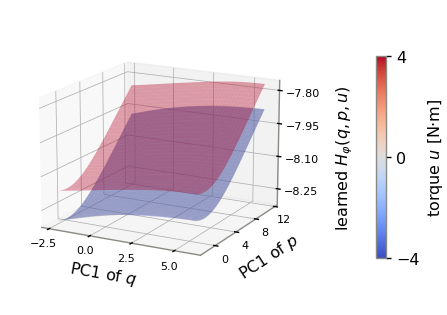

In [25]:
z = np.load(ACT / "landscape_exp079_a0q_s0.npz")
cmap_u, nrm_u = mpl.colormaps["coolwarm"], mcolors.Normalize(-4, 4)
fig = plt.figure(figsize=figsize(0.62, aspect=0.80))
ax = fig.add_subplot(111, projection="3d")
# coolwarm's midpoint is near-white, so the u = 0 surface is drawn in a neutral grey
# (the colourbar still reads it as 0) -- otherwise it vanishes against the pane.
for s_, uv in zip(z["surfs"], z["u_vals"]):
    col = "#8A8A85" if uv == 0 else cmap_u(nrm_u(uv))
    ax.plot_surface(z["GX"], z["GY"], s_, color=col, alpha=0.38, shade=False, lw=0)
ax.set_xlabel("PC1 of $q$", labelpad=-2)
ax.set_ylabel("PC1 of $p$", labelpad=-2)
ax.text2D(1.07, 0.5, r"learned $H_\varphi(q,p,u)$", transform=ax.transAxes, rotation=90,
          ha="left", va="center")
thin3d(ax)
ax.view_init(elev=16, azim=-62)
ax.set_box_aspect(None, zoom=0.88)
sm = cm.ScalarMappable(norm=nrm_u, cmap=cmap_u)
fig.colorbar(sm, ax=ax, fraction=0.035, pad=0.16, shrink=0.65, ticks=z["u_vals"]).set_label(r"torque $u$ [N·m]")
save(fig, "actuated_pendulum", "landscape_lehami", appendix=True)
plt.show()

### Planning on the actuated pendulum
Swing-up to a recorded goal state 30 steps ahead, CEM $300\times30$ with MPC, 50 test goals
$\times$ 3 planner seeds $\times$ 3 model seeds per rung of the replanning ladder
$R \in \{30, 15, 9, 6, 3\}$. Clauses at the goal instant: position
$|\theta-\theta^*|<0.1$ rad, velocity $|\omega-\omega^*|<0.5$ rad/s, and their conjunction.
Compute per episode is measured with `FlopCounterMode`; LeWM $W{=}3$ untied is charged the
tied arm's count (same tensor shapes).

In [26]:
PL, PC = ACT / "planning", ACT / "planning_compute"
CELLS = {"cell1_single_shot_H30_R30": (30, 1), "cell2_goal_H30_R15": (15, 2), "cell3_goal_H30_R9": (9, 4),
         "cell6_goal_H30_R6": (6, 5), "cell7_goal_H30_R3": (3, 10)}
PARMS = {"a0q": (r"\algo~", "hjepa"), "b0s": (r"LeWM $W{=}1$", "lewm"),
         "b3s": (r"LeWM $W{=}3$ (tied)", "lewm_w3"), "b3f": (r"LeWM $W{=}3$ (untied)", "lewm_w3")}
TOL_T, TOL_W, CAP_TFLOP = 0.1, 0.5, 15.0

fl = pd.concat([pd.read_csv(f) for f in sorted(PC.glob("*.csv"))], ignore_index=True)
fl = fl[(fl.cem_samples == 300) & (fl.cem_iters == 30)]
g_ = fl.groupby(["key", "receding"]).gflops_total
assert (g_.max() - g_.min()).max() < 1e-6, "one (arm, rung) measured at two costs"
TFLOP = (g_.mean() / 1e3).to_dict()

EPIS = []
for cdir, (R, ns) in CELLS.items():
    for tag, (label, fkey) in PARMS.items():
        for f in sorted((PL / cdir).glob(f"{tag}_s*/swingup_episodes.csv")):
            EPIS.append(pd.read_csv(f).assign(tag=tag, R=R, solves=ns, tflop=TFLOP[(fkey, R)],
                                              model_seed=int(f.parent.name.split("_s")[-1])))
EPIS = pd.concat(EPIS, ignore_index=True)
CL = {"position": lambda g: g.err_theta_at_target < TOL_T,
      "velocity": lambda g: g.err_omega_at_target < TOL_W,
      "both": lambda g: (g.err_theta_at_target < TOL_T) & (g.err_omega_at_target < TOL_W),
      "magnitude": lambda g: (g.omega_at_target.abs() - g.omega_goal.abs()).abs() < TOL_W,
      "sign": lambda g: np.sign(g.omega_at_target) == np.sign(g.omega_goal)}


def best_rung(tag, clause):
    "Best rung (mean over model seeds; population s.d.) among those under the FLOP cap."
    best = None
    for (R, ns, tf), g in EPIS[(EPIS.tag == tag) & (EPIS.tflop <= CAP_TFLOP)].groupby(["R", "solves", "tflop"]):
        per = g.groupby("model_seed").apply(lambda x: CL[clause](x).mean())
        cand = (per.mean(), per.std(ddof=0), tf, R, ns)
        best = cand if best is None or cand[0] > best[0] else best
    return best


# u = 0 coast: the true plant, same RK4 substep as the dataset generator
def coast(th, om, L, m, n_frames, dt, sub=0.0125):
    for _ in range(n_frames * int(round(dt / sub))):
        f = lambda a, b: (b, -(G / L) * np.sin(a))
        k1 = f(th, om); k2 = f(th + sub / 2 * k1[0], om + sub / 2 * k1[1])
        k3 = f(th + sub / 2 * k2[0], om + sub / 2 * k2[1]); k4 = f(th + sub * k3[0], om + sub * k3[1])
        th, om = th + sub / 6 * (k1[0] + 2 * k2[0] + 2 * k3[0] + k4[0]), om + sub / 6 * (k1[1] + 2 * k2[1] + 2 * k3[1] + k4[1])
    return th, om


args = json.loads((PL / "cell1_single_shot_H30_R30" / "a0q_s0" / "meta.json").read_text())["args"]
GOALS = EPIS[(EPIS.R == 30) & (EPIS.tag == "a0q") & (EPIS.model_seed == 0)].drop_duplicates("ep")
end = np.array([coast(r.theta0, r.omega0, r.L, r.m, args["goal_offset"], 0.05 * args["dt_mult"])
                for r in GOALS.itertuples()])
c_ = pd.DataFrame({"err_theta_at_target": np.abs(wrap(end[:, 0] - GOALS.theta_goal.to_numpy())),
                   "err_omega_at_target": np.abs(end[:, 1] - GOALS.omega_goal.to_numpy()),
                   "omega_at_target": end[:, 1], "omega_goal": GOALS.omega_goal.to_numpy()})
FLOOR = {k: float(fn(c_).mean()) for k, fn in CL.items()}
assert np.isclose(FLOOR["both"], GOALS.zero_success.mean()), "coast does not reproduce the planner's u=0 control"
print(f"{len(EPIS)} planned episodes, {EPIS.ep.nunique()} goals;  u = 0 floor: "
      + ", ".join(f"{k} {v:.3f}" for k, v in FLOOR.items()))

8100 planned episodes, 50 goals;  u = 0 floor: position 0.060, velocity 0.240, both 0.040, magnitude 0.300, sign 0.680


### Tab. `swingup-best-clause` — goal-reaching success by clause (Experiments)
Best success per model over the rungs costing at most 15 TFLOP/episode; mean $\pm$
population s.d. over three model seeds, each 150 episodes.

In [27]:
def clause_table(clauses, tags, floor=False):
    for i, (clause, name) in enumerate(clauses):
        rows = {t: best_rung(t, clause) for t in tags}
        win = max(rows, key=lambda t: rows[t][0])
        print(rf"\multirow{{{len(tags) + floor}}}{{*}}{{{name}}}")
        for t in tags:
            m, sd, tf, R, ns = rows[t]
            v = f"{m:.3f} \\pm {sd:.3f}"
            v = rf"$\mathbf{{{v}}}$" if t == win else f"${v}$"
            if t == "a0q":
                print(r"  \cmidrule{2-5}")
            print(f"  & {PARMS[t][0]:<22} & {v} & {tf:5.2f} & $R={R}$, {ns} solve{'s' if ns > 1 else ''} \\\\")
        if floor:
            print(rf"  & \textit{{$u = 0$ coast}} & \textit{{{FLOOR[clause]:.3f}}} & \textemdash & \textemdash \\")
        print(r"\midrule" if i < len(clauses) - 1 else r"\bottomrule")


clause_table([("position", "Position"), ("velocity", "Velocity"), ("both", "position and velocity")],
             ["b0s", "b3s", "b3f", "a0q"])
print(f"\ncaption: coasting with u = 0 reaches {FLOOR['position']:.3f}, {FLOOR['velocity']:.3f} and "
      f"{FLOOR['both']:.3f} on the three clauses")

\multirow{4}{*}{Position}
  & LeWM $W{=}1$           & $\mathbf{0.800 \pm 0.019}$ & 12.87 & $R=9$, 4 solves \\
  & LeWM $W{=}3$ (tied)    & $0.633 \pm 0.020$ & 13.65 & $R=9$, 4 solves \\
  & LeWM $W{=}3$ (untied)  & $0.696 \pm 0.016$ & 13.65 & $R=9$, 4 solves \\
  \cmidrule{2-5}
  & \algo~                 & $0.480 \pm 0.084$ &  8.05 & $R=9$, 4 solves \\
\midrule
\multirow{4}{*}{Velocity}
  & LeWM $W{=}1$           & $0.184 \pm 0.027$ &  8.78 & $R=15$, 2 solves \\
  & LeWM $W{=}3$ (tied)    & $0.473 \pm 0.014$ & 13.65 & $R=9$, 4 solves \\
  & LeWM $W{=}3$ (untied)  & $\mathbf{0.800 \pm 0.058}$ & 13.65 & $R=9$, 4 solves \\
  \cmidrule{2-5}
  & \algo~                 & $0.527 \pm 0.019$ & 10.98 & $R=6$, 5 solves \\
\midrule
\multirow{4}{*}{position and velocity}
  & LeWM $W{=}1$           & $0.142 \pm 0.033$ & 12.87 & $R=9$, 4 solves \\
  & LeWM $W{=}3$ (tied)    & $0.400 \pm 0.030$ &  9.17 & $R=15$, 2 solves \\
  & LeWM $W{=}3$ (untied)  & $\mathbf{0.636 \pm 0.028}$ & 13.65 & $R=9$, 4 so

### Tab. `swingup-clause-decomp` — the velocity clause split into magnitude and sign (Appendix)
Magnitude: $\big||\omega|-|\omega^*|\big| < 0.5$ rad/s; sign: $\mathrm{sign}\,\omega =
\mathrm{sign}\,\omega^*$. Same selection rule and cap as above.

In [28]:
clause_table([("magnitude", "Velocity, magnitude"), ("sign", "Velocity, sign")], ["b0s", "b3s", "a0q"], floor=True)
print(f"\ngoals with 2|omega*| >= tau_omega (sign decisive): "
      f"{(2 * GOALS.omega_goal.abs() >= TOL_W).mean():.0%}")

\multirow{4}{*}{Velocity, magnitude}
  & LeWM $W{=}1$           & $0.251 \pm 0.051$ &  8.78 & $R=15$, 2 solves \\
  & LeWM $W{=}3$ (tied)    & $\mathbf{0.638 \pm 0.008}$ & 13.65 & $R=9$, 4 solves \\
  \cmidrule{2-5}
  & \algo~                 & $0.547 \pm 0.022$ & 10.98 & $R=6$, 5 solves \\
  & \textit{$u = 0$ coast} & \textit{0.300} & \textemdash & \textemdash \\
\midrule
\multirow{4}{*}{Velocity, sign}
  & LeWM $W{=}1$           & $0.656 \pm 0.017$ &  5.85 & $R=30$, 1 solve \\
  & LeWM $W{=}3$ (tied)    & $0.649 \pm 0.022$ & 13.65 & $R=9$, 4 solves \\
  \cmidrule{2-5}
  & \algo~                 & $\mathbf{0.800 \pm 0.034}$ &  8.05 & $R=9$, 4 solves \\
  & \textit{$u = 0$ coast} & \textit{0.680} & \textemdash & \textemdash \\
\bottomrule

goals with 2|omega*| >= tau_omega (sign decisive): 92%


### Fig. `goal-distribution` — the planning goals (Appendix)
The 50 test goals shared by every arm, rung and seed: goal velocity $\omega^*$ and goal
angle $\theta^*$ (wrapped).

wrote figures/actuated_pendulum/goal_distribution_appendix.png


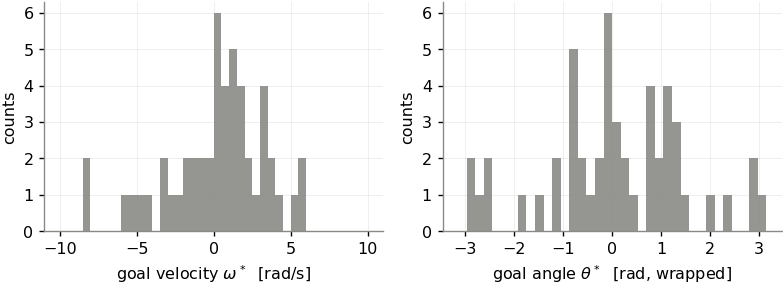

50 goals;  |omega*| median 1.66, max 8.49 rad/s


In [29]:
fig, AX = plt.subplots(1, 2, figsize=figsize())
AX[0].hist(GOALS.omega_goal, bins=np.linspace(-10, 10, 41), color=C["control"], alpha=0.9)
AX[0].set(xlabel=r"goal velocity $\omega^*$  [rad/s]", ylabel="counts")
AX[1].hist(wrap(GOALS.theta_goal), bins=np.linspace(-np.pi, np.pi, 37), color=C["control"], alpha=0.9)
AX[1].set(xlabel=r"goal angle $\theta^*$  [rad, wrapped]", ylabel="counts")
fig.tight_layout()
save(fig, "actuated_pendulum", "goal_distribution", appendix=True)
plt.show()
a = GOALS.omega_goal.abs()
print(f"{len(GOALS)} goals;  |omega*| median {a.median():.2f}, max {a.max():.2f} rad/s")

---
### Output index

In [30]:
for p in sorted(FIG.rglob("*.png")):
    if "_old" not in p.parts and "_pdf_preview" not in p.parts:
        print(p.relative_to(FIG))

actuated_pendulum/canonicality_lehami_vs_lewm_w1_w3_appendix.png
actuated_pendulum/goal_distribution_appendix.png
actuated_pendulum/landscape_lehami_appendix.png
actuated_pendulum/rollout_lehami_vs_lewm_w1_w3_appendix.png
conservative_pendulum/dino_physics_rollout_appendix.png
conservative_pendulum/dt_and_reversal.png
conservative_pendulum/energy_conservation_projections_appendix.png
conservative_pendulum/jacobian_volume_k0_appendix.png
conservative_pendulum/paper_energy_level_sets_appendix.png
conservative_pendulum/physical_vs_lehami_appendix.png
conservative_pendulum/physics_rollout.png
datasets/datasets_strip_pendula.png
datasets/dif_lengths_pendulum_appendix.png
datasets/example_data_pendulum_appendix.png
dino_physics_rollout.png
dt_and_reversal.png
physics_rollout_new.png
